# Random partitions priors on static stochastic block model

Author: **Carlos Nosa** - Date: **10-2026**

This notebook studies the stochastic block model (SBM) under different prior specifications for latent community partitioning and different Bayesian inference algorithms. We consider five prior distributions for random partitioning: the Dirichlet-multinomial (DM), Dirichlet process (DP), Pitman-Yor (PY), Gnedin (GN), and Mixture of Finite Mixtures (MFM) prior distributions. For posterior inference, we consider Gibbs sampling, split-merge sampling, and Chaperone-based inference.

We are going to use the following libraries:

In [13]:
from collections.abc import Callable
from abc import ABC, abstractmethod
from dataclasses import dataclass
from typing import Literal
import numpy as np
import networkx as nx
import pandas as pd
from numpy.typing import NDArray
from scipy.special import betaln, gammaln, logsumexp
from itertools import combinations
from tqdm import tqdm
FloatArray = NDArray[np.float64]
IntArray = NDArray[np.int64]

## SBMModel

First, we create a class that will contain the stochastic block model without specifying any prior distribution associated with the partition and by specifying a Beta distribution for the prior distribution of the probabilities of interaction between communities.

In [2]:
@dataclass(frozen=True)
class SBMModel:
    """
    Bayesian SBM for undirected, binary networks without self-loops.

    Model:
        Y_ij | z, theta ~ Bernoulli(theta[z_i, z_j]), i < j
        theta_hk ~ Beta(a, b)

    The probabilities theta are integrated analytically.

    Parameters
    ----------
    adjacency : array-like
        Symmetric, binary adjacency matrix with a zero diagonal.
    a, b : float
        Positive parameters of the Beta prior on the connection probabilities
        between blocks.
    """

    adjacency: NDArray
    a: float = 1.0
    b: float = 1.0

    def __post_init__(self) -> None:
        # Crear una copia para evitar modificar los datos originales.
        Y = np.array(self.adjacency, dtype=np.float64, copy=True)

        if Y.ndim != 2 or Y.shape[0] != Y.shape[1]:
            raise ValueError("The adjacency matrix must be square.")

        if Y.shape[0] < 2:
            raise ValueError("The network must contain at least two nodes.")

        if not np.all(np.isfinite(Y)):
            raise ValueError("The matrix contains non-finite values.")

        if not np.allclose(Y, Y.T):
            raise ValueError("The matrix must be symmetric.")

        if not np.all((Y == 0) | (Y == 1)):
            raise ValueError("The matrix must contain only 0 and 1.")
        if not np.all(np.diag(Y) == 0):
            raise ValueError("Self-loops are not allowed: the diagonal must be zero.")

        if not np.isfinite(self.a) or not np.isfinite(self.b):
            raise ValueError("The parameters a and b must be finite.")

        if self.a <= 0 or self.b <= 0:
            raise ValueError("The parameters a and b must be positive.")

        Y.setflags(write=False)
        object.__setattr__(self, "adjacency", Y)
        object.__setattr__(self, "a", float(self.a))
        object.__setattr__(self, "b", float(self.b))

    @property
    def n_nodes(self) -> int:
        """Number of nodes in the network."""
        return self.adjacency.shape[0]

    @staticmethod
    def _canonicalize_partition(z: NDArray) -> IntArray:
        """
        Converts the labels to consecutive integers starting from zero.

        Example:
            [5, 5, 9, 9, 5] -> [0, 0, 1, 1, 0]
        """
        z = np.asarray(z)

        if z.ndim != 1:
            raise ValueError("The partition must be a one-dimensional array.")

        if not np.issubdtype(z.dtype, np.integer):
            raise ValueError("The labels must be integers.")

        if z.size == 0:
            raise ValueError("The partition cannot be empty.")

        _, inverse = np.unique(z, return_inverse=True)
        return inverse.astype(np.int64)

    def _validate_partition(self, z: NDArray) -> IntArray:
        """Validates the partition with respect to the number of nodes."""
        z = self._canonicalize_partition(z)

        if len(z) != self.n_nodes:
            raise ValueError(
                f"Expected {self.n_nodes} labels; "
                f"received {len(z)}."
            )

        return z

    def block_statistics(self, z: NDArray) -> dict[str, NDArray]:
        """
        Compute the sufficient statistics by block.

        Returns
        -------
        dict
            labels: canonical labels.
            sizes: sizes of the blocks.
            edges: number of edges per block.
            non_edges: number of non-edges per block.

        Each unordered pair is counted once.
        """
        z = self._validate_partition(z)

        n_blocks = int(z.max()) + 1
        sizes = np.bincount(z, minlength=n_blocks)

        # Contar aristas entre bloques.
        edges = np.zeros((n_blocks, n_blocks), dtype=np.float64)

        rows, cols = np.triu_indices(self.n_nodes, k=1)

        block_i = np.minimum(z[rows], z[cols])
        block_j = np.maximum(z[rows], z[cols])

        edges = np.zeros((n_blocks, n_blocks), dtype=np.float64)

        np.add.at(edges, (block_i, block_j), self.adjacency[rows, cols])

        edges = edges + np.triu(edges, k=1).T

        # Número total de pares posibles entre bloques.
        possible = np.outer(sizes, sizes).astype(np.float64)
        diagonal = np.diag_indices(n_blocks)
        possible[diagonal] = sizes * (sizes - 1) / 2

        non_edges = possible - edges

        return {
            "labels": z,
            "sizes": sizes,
            "edges": edges,
            "non_edges": non_edges,
        }

    def log_marginal_likelihood(self, z: NDArray) -> float:
        """
        Compute log p(Y | z), integrating out the theta probabilities.

        log p(Y | z) =
            sum_{h <= k} [
                log B(a + edges_hk, b + non_edges_hk)
                - log B(a, b)
            ]
        """
        stats = self.block_statistics(z)
        edges = stats["edges"]
        non_edges = stats["non_edges"]

        upper = np.triu_indices_from(edges)

        log_prob = (
            betaln(self.a + edges[upper],
                   self.b + non_edges[upper])
            - betaln(self.a, self.b)
        )

        return float(np.sum(log_prob))

    def log_posterior(self, z: NDArray, log_prior: Callable[[IntArray], float] | None = None,) -> float:
        """
        Compute the log-posterior of the partition, up to a constant:

            log p(z | Y) = log p(Y | z) + log p(z) + C.

        If log_prior is None, returns only log p(Y | z).
        If provided, it should return log p(z) for the partition.
        """
        z = self._validate_partition(z)
        value = self.log_marginal_likelihood(z)

        if log_prior is not None:
            prior_value = float(log_prior(z.copy()))

            if not np.isfinite(prior_value):
                return prior_value

            value += prior_value

        return float(value)

Example

In [3]:
Y = np.array([
    [0, 1, 1, 0, 0, 0],
    [1, 0, 1, 0, 0, 0],
    [1, 1, 0, 1, 0, 0],
    [0, 0, 1, 0, 1, 1],
    [0, 0, 0, 1, 0, 1],
    [0, 0, 0, 1, 1, 0],
])

z = np.array([0, 0, 0, 1, 1, 1])

model = SBMModel(adjacency=Y, a=1.0, b=1.0)

print("Number of nodes:", model.n_nodes)
print("Block statistics:")
print(model.block_statistics(z))
print("Log-marginal likelihood:", model.log_marginal_likelihood(z))
print("Log-posterior without prior:", model.log_posterior(z))

Number of nodes: 6
Block statistics:
{'labels': array([0, 0, 0, 1, 1, 1]), 'sizes': array([3, 3]), 'edges': array([[3., 1.],
       [1., 3.]]), 'non_edges': array([[0., 8.],
       [8., 0.]])}
Log-marginal likelihood: -7.272398392570047
Log-posterior without prior: -7.272398392570047


## PartitionPrior

The next step is to create a class that contains the partition preview as a random partition.

In [4]:
PriorName = Literal["DP", "PY", "DM", "GN", "MFM"]
@dataclass(frozen=True)
class PartitionPrior:
    """
    Prior distributions over node partitions.

    Priors
    ------------------
    DP  : Dirichlet Process.
    PY  : Pitman-Yor Process.
    DM  : Dirichlet-Multinomial with H_total categories.
    GN  : Urn scheme de Gnedin.
    MFM : Mixture of Finite Mixtures.

    Parameters
    ----------
    kind : {"DP", "PY", "DM", "GN", "MFM"}
        Type of prior.
    alpha : float, optional
        Concentration parameter for DP and PY.
    sigma : float, optional
        Discount parameter for PY.
    beta : float, optional
        Category parameter for DM.
    H_total : int, optional
        Maximum number of categories for DM.
    gamma : float, optional
        Parameter of the GN scheme.
    rho : float, optional
        Symmetric Dirichlet parameter for MFM.
    p_k : tuple[float, ...], optional
        Probabilities P(K=m), for m=1,...,M.
        Automatically normalized.
    """

    kind: PriorName
    alpha: float | None = None
    sigma: float | None = None
    beta: float | None = None
    H_total: int | None = None
    gamma: float | None = None
    rho: float | None = None
    p_k: tuple[float, ...] | None = None

    def __post_init__(self) -> None:
        kind = self.kind.upper()

        if kind not in {"DP", "PY", "DM", "GN", "MFM"}:
            raise ValueError("kind should ber DP, PY, DM, GN o MFM.")

        object.__setattr__(self, "kind", kind)

        if kind in {"DP", "PY"}:
            if self.alpha is None or not np.isfinite(self.alpha):
                raise ValueError("Requieres finite alpha.")

            if kind == "DP" and self.alpha <= 0:
                raise ValueError("For DP, alpha should be positive.")

        if kind == "PY":
            if self.sigma is None or not np.isfinite(self.sigma):
                raise ValueError("PY requires finite sigma.")

            if not 0 <= self.sigma < 1:
                raise ValueError("PY requires 0 <= sigma < 1.")

            if self.alpha <= -self.sigma:
                raise ValueError("PY requires alpha > -sigma.")

        if kind == "DM":
            if self.beta is None or not np.isfinite(self.beta) or self.beta <= 0:
                raise ValueError("DM requires beta positive and finite.")

            if (
                self.H_total is None
                or not isinstance(self.H_total, (int, np.integer))
                or self.H_total < 1
            ):
                raise ValueError("DM requires H_total positive integer.")

        if kind == "GN":
            if self.gamma is None or not np.isfinite(self.gamma):
                raise ValueError("GN requires finite gamma.")

            if not 0 < self.gamma < 1:
                raise ValueError("GN requires 0 < gamma < 1.")

        if kind == "MFM":
            if self.rho is None or not np.isfinite(self.rho) or self.rho <= 0:
                raise ValueError("MFM requires rho positive and finite.")

            if self.p_k is None:
                raise ValueError("MFM requires specifying p_k.")

            p_k = np.asarray(self.p_k, dtype=float)

            if (
                p_k.ndim != 1
                or p_k.size == 0
                or np.any(~np.isfinite(p_k))
                or np.any(p_k < 0)
                or p_k.sum() <= 0
            ):
                raise ValueError("p_k should be a vector of non-negative probabilities with positive sum.")

            p_k = p_k / p_k.sum()
            object.__setattr__(self, "p_k", tuple(p_k))

    @staticmethod
    def _canonicalize(z: NDArray) -> IntArray:
        """Rename the communities according to their first appearance."""
        z = np.asarray(z)

        if z.ndim != 1 or z.size == 0:
            raise ValueError("z should be a non-empty vector.")

        if not np.issubdtype(z.dtype, np.integer):
            raise ValueError("Labels must be integers.")

        mapping = {}
        canonical = np.empty(len(z), dtype=np.int64)

        for i, label in enumerate(z):
            label = int(label)

            if label not in mapping:
                mapping[label] = len(mapping)

            canonical[i] = mapping[label]

        return canonical

    @staticmethod
    def _sizes(z: IntArray) -> IntArray:
        """Returns the sizes of the non-empty communities."""
        return np.bincount(z)

    def _log_V(self, n: int, k: int) -> float:
        """
        Calculates log V_n(k) for MFM using log-sum-exp.

        p_k[m-1] = P(K=m), for m=1,...,M.
        """
        if self.kind != "MFM":
            raise ValueError("_log_V is only available for MFM.")

        if k < 1 or n < k:
            return -np.inf

        p_k = np.asarray(self.p_k, dtype=float)
        m_all = np.arange(1, len(p_k) + 1)

        valid = (m_all >= k) & (p_k > 0)

        if not np.any(valid):
            return -np.inf

        m = m_all[valid].astype(float)
        probs = p_k[valid]

        log_terms = (
            gammaln(m + 1)
            - gammaln(m - k + 1)
            + gammaln(m * self.rho)
            - gammaln(m * self.rho + n)
            + np.log(probs)
        )

        return float(logsumexp(log_terms))

    def log_probability(self, z: NDArray) -> float:
        """
        Calculates the log-probability of a partition.

        For DP, PY, DM and MFM, it uses their respective EPPFs.
        For GN, it uses the sequential probability induced
        by the urn weights.
        """
        z = self._canonicalize(z)
        sizes = self._sizes(z)

        n = len(z)
        K = len(sizes)

        if self.kind == "DP":
            alpha = self.alpha

            return float(
                gammaln(alpha)
                - gammaln(alpha + n)
                + K * np.log(alpha)
                + np.sum(gammaln(sizes))
            )

        if self.kind == "PY":
            alpha = self.alpha
            sigma = self.sigma

            if K == 1:
                log_product = 0.0
            else:
                j = np.arange(1, K, dtype=float)
                terms = alpha + j * sigma

                if np.any(terms <= 0):
                    return -np.inf

                log_product = np.sum(np.log(terms))

            return float(
                log_product
                + gammaln(alpha + 1)
                - gammaln(alpha + n)
                + np.sum(
                    gammaln(sizes - sigma)
                    - gammaln(1 - sigma)
                )
            )

        if self.kind == "DM":
            beta = self.beta
            H = self.H_total

            if K > H:
                return -np.inf

            log_injections = (
                gammaln(H + 1)
                - gammaln(H - K + 1)
            )

            return float(
                log_injections
                + gammaln(H * beta)
                - gammaln(n + H * beta)
                + np.sum(
                    gammaln(sizes + beta)
                    - gammaln(beta)
                )
            )

        if self.kind == "MFM":
            log_v = self._log_V(n, K)

            if not np.isfinite(log_v):
                return -np.inf

            rho = self.rho

            return float(
                log_v
                + np.sum(
                    gammaln(sizes + rho)
                    - gammaln(rho)
                )
            )

        # GN
        log_prob = 0.0
        current_sizes = np.array([1], dtype=np.int64)

        for i in range(1, n):
            weights = self.urn_weights(current_sizes)
            total = weights.sum()
            target = int(z[i])

            if not np.isfinite(total) or total <= 0:
                raise ValueError("The GN weights are not normalizable.")

            if target < len(current_sizes):
                weight = weights[target]
            else:
                if target != len(current_sizes):
                    raise ValueError("Not canonical partition.")
                weight = weights[-1]

            if weight <= 0:
                return -np.inf

            log_prob += np.log(weight / total)

            if target == len(current_sizes):
                current_sizes = np.append(current_sizes, 1)
            else:
                current_sizes[target] += 1

        return float(log_prob)

    def urn_weights(self, sizes: NDArray) -> FloatArray:
        """
        Returns weights for existing communities and a new one.

        The last element corresponds to creating a new community.
        The weights are relative; predictive_probabilities() normalizes them.
        """
        sizes = np.asarray(sizes, dtype=np.float64)

        if sizes.ndim != 1 or sizes.size == 0 or np.any(sizes <= 0):
            raise ValueError("sizes must contain positive values.")

        K = len(sizes)
        n = int(sizes.sum())

        if self.kind == "DP":
            weights = np.append(sizes, self.alpha)

        elif self.kind == "PY":
            weights = np.append(
                sizes - self.sigma,
                self.alpha + K * self.sigma,
            )

        elif self.kind == "DM":
            if K > self.H_total:
                raise ValueError("There are more communities than H_total.")

            weights = np.append(
                sizes + self.beta,
                self.beta * (self.H_total - K),
            )

        elif self.kind == "MFM":
            log_v_n_k = self._log_V(n, K)

            if not np.isfinite(log_v_n_k):
                raise ValueError(
                    "The partition has zero prior probability under MFM."
                )

            log_v_next_k = self._log_V(n + 1, K)
            log_v_next_k1 = self._log_V(n + 1, K + 1)

            existing_ratio = (
                0.0
                if not np.isfinite(log_v_next_k)
                else np.exp(log_v_next_k - log_v_n_k)
            )

            new_ratio = (
                0.0
                if not np.isfinite(log_v_next_k1)
                else np.exp(log_v_next_k1 - log_v_n_k)
            )

            weights = np.append(
                (sizes + self.rho) * existing_ratio,
                self.rho * new_ratio,
            )

        else:  # GN: weights from the reference code of Legramanti (2022).
            gamma = self.gamma

            existing = (sizes + 1) * (n - K + gamma)
            new = K**2 - K * gamma

            weights = np.append(existing, new)

        if np.any(~np.isfinite(weights)) or np.any(weights < 0):
            raise ValueError("The prior produced invalid weights.")

        if weights.sum() <= 0:
            raise ValueError("The sum of the weights must be positive.")

        return weights.astype(np.float64)

    def predictive_probabilities(self, sizes: NDArray) -> FloatArray:
        """Normalizes the weights to obtain predictive probabilities."""
        weights = self.urn_weights(sizes)
        return weights / weights.sum()

Example

In [5]:
z = np.array([0, 0, 1, 1, 1, 2, 2, 2, 1])
z_renamed = np.array([7, 7, 3, 3, 3, 9, 9, 9, 3])

priors = {
    "DP": PartitionPrior(kind="DP", alpha=1.5),
    "PY": PartitionPrior(kind="PY", alpha=1.0, sigma=0.2),
    "DM": PartitionPrior(kind="DM", beta=1.0, H_total=5),
    "GN": PartitionPrior(kind="GN", gamma=0.4),
    "MFM": PartitionPrior(kind="MFM", rho=1.0, p_k= tuple(0.5 * (1 - 0.5) ** np.arange(10))),
}

for name, prior in priors.items():
    lp = prior.log_probability(z)
    lp_renamed = prior.log_probability(z_renamed)

    assert np.isclose(lp, lp_renamed)
    print(f"{name}: log-prior = {lp:.6f}")

DP: log-prior = -10.360105
PY: log-prior = -10.747272
DM: log-prior = -9.616805
GN: log-prior = -11.191618
MFM: log-prior = -10.846525


In [6]:
sizes = np.array([3, 2, 1])

for name, prior in priors.items():
    probabilities = prior.predictive_probabilities(sizes)

    assert np.all(probabilities >= 0)
    assert np.isclose(probabilities.sum(), 1.0)

    print(
        f"{name}: probabilities = {np.round(probabilities, 4)}, "
        f"sum = {probabilities.sum():.4f}"
    )

DP: probabilities = [0.4    0.2667 0.1333 0.2   ], sum = 1.0000
PY: probabilities = [0.4    0.2571 0.1143 0.2286], sum = 1.0000
DM: probabilities = [0.3636 0.2727 0.1818 0.1818], sum = 1.0000
GN: probabilities = [0.3542 0.2656 0.1771 0.2031], sum = 1.0000
MFM: probabilities = [0.4046 0.3035 0.2023 0.0896], sum = 1.0000


## Sampler

Now we'll move on to a class that serves as a sampler; from here, we'll use inheritance to create specific instances of algorithms.

In [14]:
@dataclass(frozen=True)
class SamplerConfig:
    n_iterations: int = 5_000
    burn_in: int = 1_000
    thin: int = 5

    def __post_init__(self):
        if self.n_iterations < 1:
            raise ValueError("n_iterations must be a positive integer.")
        if not 0 <= self.burn_in < self.n_iterations:
            raise ValueError("burn_in must be an integer between 0 and n_iterations.")
        if self.thin < 1:
            raise ValueError("thin must be a positive integer.")


class BaseSampler(ABC):
    """Base class for MCMC samplers of SBM partitions."""

    def __init__(
        self,
        model: SBMModel,
        prior: PartitionPrior,
        config: SamplerConfig | None = None,
    ):
        self.model = model
        self.prior = prior
        self.config = config or SamplerConfig()

    @staticmethod
    def _canonicalize(z: NDArray) -> NDArray[np.int64]:
        """Renames blocks according to their first appearance."""
        z = np.asarray(z)

        if z.ndim != 1 or not np.issubdtype(z.dtype, np.integer):
            raise ValueError("The partition must be a vector of integers.")

        mapping = {}
        result = np.empty(len(z), dtype=np.int64)

        for i, label in enumerate(z):
            label = int(label)
            if label not in mapping:
                mapping[label] = len(mapping)
            result[i] = mapping[label]

        return result

    def log_target(self, z: NDArray) -> float:
        """Not noramlized log-posterior of the partition."""
        return self.model.log_posterior(z, log_prior=self.prior.log_probability,)

    @abstractmethod
    def _step(
        self,
        z: NDArray[np.int64],
        rng: np.random.Generator,
    ) -> NDArray[np.int64]:
        """Executes a transition of the algorithm."""
        raise NotImplementedError

    def fit(
        self,
        initial_partition: NDArray,
        seed: int = 42,
    ) -> dict[str, object]:
        """Executes the chain and saves samples and traces."""

        z = self._canonicalize(initial_partition)

        if len(z) != self.model.n_nodes:
            raise ValueError("The partition must have a label for each node.")

        rng = np.random.default_rng(seed)
        samples = []
        log_posterior_trace = []
        n_communities_trace = []

        for iteration in tqdm(range(self.config.n_iterations),desc="Sampling"):
            z = self._canonicalize(self._step(z.copy(), rng))

            log_posterior_trace.append(self.log_target(z))
            n_communities_trace.append(len(np.unique(z)))

            if (
                iteration >= self.config.burn_in
                and (iteration - self.config.burn_in) % self.config.thin == 0
            ):
                samples.append(z.copy())

        return {
            "samples": np.asarray(samples, dtype=np.int64),
            "log_posterior": np.asarray(log_posterior_trace),
            "n_communities": np.asarray(n_communities_trace),
            "final_partition": z.copy(),
            "seed": seed,
        }

### Gibbs sampler

In [15]:
class GibbsSampler(BaseSampler):
    """Collapsed Gibbs sampler with reassignment of one node at a time."""
    def _step(self, z: NDArray[np.int64], rng: np.random.Generator,) -> NDArray[np.int64]:
        n = len(z)
        # Random walk over nodes to avoid a fixed order.
        for i in rng.permutation(n):
            mask = np.arange(n) != i
            # Remove the node and eliminate empty blocks.
            z_minus = self._canonicalize(z[mask])
            n_blocks = len(np.unique(z_minus))
            log_weights = []
            candidates = []
            # Test all existing communities and a new one.
            for k in range(n_blocks + 1):
                candidate = np.empty(n, dtype=np.int64)
                candidate[mask] = z_minus
                candidate[i] = k
                candidate = self._canonicalize(candidate)
                log_weight = self.log_target(candidate)
                candidates.append(candidate)
                log_weights.append(log_weight)
            log_weights = np.asarray(log_weights, dtype=float)
            if np.all(np.isneginf(log_weights)):
                raise RuntimeError("All candidate assignments have a posterior probability of zero.")
            probabilities = np.exp(log_weights - logsumexp(log_weights))
            selected = rng.choice(len(candidates),p=probabilities,)
            z = candidates[selected].copy()
        return self._canonicalize(z)

Example

In [16]:
Y = np.array([
    [0, 1, 1, 0, 0, 0],
    [1, 0, 1, 0, 0, 0],
    [1, 1, 0, 1, 0, 0],
    [0, 0, 1, 0, 1, 1],
    [0, 0, 0, 1, 0, 1],
    [0, 0, 0, 1, 1, 0],])
model = SBMModel(adjacency=Y, a=1.0, b=1.0)
prior = PartitionPrior(kind="DP", alpha=1.5,)
config = SamplerConfig(n_iterations=1500, burn_in=100, thin=5,)
sampler = GibbsSampler(model=model, prior=prior, config=config,)
result = sampler.fit(initial_partition=np.array([0, 0, 0, 1, 1, 1]), seed=123,)
print("Sample shape:", result["samples"].shape)
print("Final number of communities:", len(np.unique(result["final_partition"])))
print(result["samples"][-2:])

Sampling: 100%|██████████| 1500/1500 [00:30<00:00, 49.52it/s]

Sample shape: (280, 6)
Final number of communities: 4
[[0 1 0 2 2 3]
 [0 1 0 2 2 3]]


In [17]:
samples = result["samples"]
n_communities = np.array([len(np.unique(z)) for z in samples])
values, counts = np.unique(n_communities, return_counts=True,)
frequencies = counts / counts.sum()
for k, frequency in zip(values, frequencies):
    print(f"K = {k}: frequency = {frequency:.3f}")

K = 1: frequency = 0.039
K = 2: frequency = 0.236
K = 3: frequency = 0.364
K = 4: frequency = 0.300
K = 5: frequency = 0.061


Example "4 nodes"

In [18]:
Y4 = np.array([
    [0, 1, 1, 0],
    [1, 0, 1, 1],
    [1, 1, 0, 1],
    [0, 1, 1, 0]], dtype=int)

a = 1.0
b = 1.0
alpha = 1.5
assert Y4.shape == (4, 4)
assert np.array_equal(Y4, Y4.T)
assert np.all(np.diag(Y4) == 0)
assert np.all(np.isin(Y4, [0, 1]))
print("Number of nodes:", len(Y4))
print("Number of edges:", int(np.triu(Y4, k=1).sum()))


def enumerate_partitions(n):
    """Enumerates all partitions of n elements."""
    if n < 1:
        raise ValueError("n must be positive.")
    partitions = []
    def recurse(z, max_label):
        i = len(z)
        if i == n:
            partitions.append(tuple(z))
            return
        for label in range(max_label + 2):
            recurse(z + [label], max(max_label, label))
    recurse([0], 0)
    return partitions


partitions = enumerate_partitions(4)

print("Partitions enumerated:", len(partitions))
assert len(partitions) == 15
assert len(set(partitions)) == 15


def log_marginal_sbm(Y, z, a=1.0, b=1.0):
    """Log-likelihood marginal of a binary undirected SBM."""
    Y = np.asarray(Y)
    z = np.asarray(z)
    n = len(z)
    if Y.shape != (n, n):
        raise ValueError("Incompatible dimensions between Y and z.")
    if not np.array_equal(Y, Y.T):
        raise ValueError("Y must be symmetric.")
    if np.any(np.diag(Y) != 0):
        raise ValueError("Y must have a zero diagonal.")
    if not np.all(np.isin(Y, [0, 1])):
        raise ValueError("Y must be binary.")
    if a <= 0 or b <= 0:
        raise ValueError("a and b must be positive.")
    labels = sorted(set(z))
    total = 0.0

    for pos, h in enumerate(labels):
        for k in labels[pos:]:
            nodes_h = np.flatnonzero(z == h)
            nodes_k = np.flatnonzero(z == k)
            if h == k:
                possible = len(nodes_h) * (len(nodes_h) - 1) // 2
                subgraph = Y[np.ix_(nodes_h, nodes_h)]
                edges = int(np.triu(subgraph, k=1).sum())
            else:
                possible = len(nodes_h) * len(nodes_k)
                edges = int(Y[np.ix_(nodes_h, nodes_k)].sum())

            non_edges = possible - edges

            total += betaln(a + edges, b + non_edges) - betaln(a, b)
    return float(total)

def log_prior_dp(z, alpha=1.5):
    z = np.asarray(z)
    n = len(z)
    sizes = np.unique(z, return_counts=True)[1]
    K = len(sizes)
    return gammaln(alpha) - gammaln(alpha + n) + K * np.log(alpha) + np.sum(gammaln(sizes)) 


log_priors = np.array([log_prior_dp(z, alpha) for z in partitions])
prior_probabilities = np.exp(log_priors)
print("Sum of prior probabilities:", prior_probabilities.sum())
assert np.isclose(prior_probabilities.sum(), 1.0)
log_likelihoods = np.array([log_marginal_sbm(Y4, z, a, b) for z in partitions])
log_joint = log_likelihoods + log_priors
log_evidence = logsumexp(log_joint)
exact_probabilities = np.exp(log_joint - log_evidence)
print("Sum of posterior probabilities:", exact_probabilities.sum())
assert np.isclose(exact_probabilities.sum(), 1.0)
order = np.argsort(exact_probabilities)[::-1]

print("\n Fifteen partitions with highest posterior probability:")
for idx in order[:15]:
    print(f"z={partitions[idx]}, "
        f"K={len(set(partitions[idx]))}, "
        f"p(z|Y)={exact_probabilities[idx]:.6f}" )

Number of nodes: 4
Number of edges: 5
Partitions enumerated: 15
Sum of prior probabilities: 1.0
Sum of posterior probabilities: 0.9999999999999998

 Fifteen partitions with highest posterior probability:
z=(0, 0, 0, 0), K=1, p(z|Y)=0.176783
z=(0, 1, 1, 0), K=2, p(z|Y)=0.092811
z=(0, 1, 2, 0), K=3, p(z|Y)=0.077343
z=(0, 1, 1, 2), K=3, p(z|Y)=0.077343
z=(0, 1, 1, 1), K=2, p(z|Y)=0.077343
z=(0, 1, 0, 0), K=2, p(z|Y)=0.077343
z=(0, 0, 1, 0), K=2, p(z|Y)=0.077343
z=(0, 0, 0, 1), K=2, p(z|Y)=0.077343
z=(0, 1, 2, 3), K=4, p(z|Y)=0.065258
z=(0, 1, 2, 2), K=3, p(z|Y)=0.038671
z=(0, 1, 2, 1), K=3, p(z|Y)=0.038671
z=(0, 1, 0, 2), K=3, p(z|Y)=0.038671
z=(0, 0, 1, 2), K=3, p(z|Y)=0.038671
z=(0, 1, 0, 1), K=2, p(z|Y)=0.023203
z=(0, 0, 1, 1), K=2, p(z|Y)=0.023203


In [19]:
model4 = SBMModel(adjacency=Y4, a=a, b=b)
prior4 = PartitionPrior(kind="DP", alpha=alpha)
config4 = SamplerConfig(n_iterations=105_000, burn_in=5_000,thin=10)
sampler4 = GibbsSampler(model=model4,prior=prior4,config=config4)
result4 = sampler4.fit(initial_partition=np.array([0, 0, 1, 1]), seed=123)
def canonical_partition(z):
    mapping = {}
    result = []
    for label in z:
        if label not in mapping:
            mapping[label] = len(mapping)
        result.append(mapping[label])
    return tuple(result)
samples = result4["samples"]
if isinstance(samples, np.ndarray) and samples.ndim == 2:
    samples = [canonical_partition(z) for z in samples]
else:
    samples = [canonical_partition(z) for z in samples]
exact_map = {z: p for z, p in zip(partitions, exact_probabilities)}
counts = {z: 0 for z in partitions}
for z in samples:
    counts[z] += 1
empirical = np.array([counts[z] / len(samples) for z in partitions])
exact = np.array([exact_map[z] for z in partitions])
tv_distance = 0.5 * np.sum(np.abs(empirical - exact))
print("Number of samples:", len(samples))
print("Total variation distance:", tv_distance)
print("\nComparison of probabilities:")
for idx in order:
    print(f"{partitions[idx]} | "
        f"exact={exact[idx]:.4f} | "
        f"Gibbs={empirical[idx]:.4f}")

Sampling: 100%|██████████| 105000/105000 [15:45<00:00, 111.02it/s]

Number of samples: 10000
Total variation distance: 0.01385708859885365

Comparison of probabilities:
(0, 0, 0, 0) | exact=0.1768 | Gibbs=0.1766
(0, 1, 1, 0) | exact=0.0928 | Gibbs=0.0943
(0, 1, 2, 0) | exact=0.0773 | Gibbs=0.0808
(0, 1, 1, 2) | exact=0.0773 | Gibbs=0.0789
(0, 1, 1, 1) | exact=0.0773 | Gibbs=0.0717
(0, 1, 0, 0) | exact=0.0773 | Gibbs=0.0746
(0, 0, 1, 0) | exact=0.0773 | Gibbs=0.0785
(0, 0, 0, 1) | exact=0.0773 | Gibbs=0.0743
(0, 1, 2, 3) | exact=0.0653 | Gibbs=0.0662
(0, 1, 2, 2) | exact=0.0387 | Gibbs=0.0382
(0, 1, 2, 1) | exact=0.0387 | Gibbs=0.0384
(0, 1, 0, 2) | exact=0.0387 | Gibbs=0.0416
(0, 0, 1, 2) | exact=0.0387 | Gibbs=0.0398
(0, 1, 0, 1) | exact=0.0232 | Gibbs=0.0244
(0, 0, 1, 1) | exact=0.0232 | Gibbs=0.0217


### Split-merge

In [20]:
class SplitMergeSampler(BaseSampler):
    """
    MCMC split-merge for partitions of an SBM.
    If the chosen nodes are in the same block:
        propose to split it.
    If they are in different blocks:
        propose to merge them.
    The acceptance includes the Metropolis-Hastings correction.
    """
    def _step(self, z, rng):
        z = self._canonicalize(z.copy())
        n = len(z)
        # Choose two distinct nodes uniformly at random.
        i, j = rng.choice(n, size=2, replace=False)
        same_block = z[i] == z[j]
        if same_block:
            old_block = z[i]
            members = np.flatnonzero(z == old_block)
            candidate = z.copy()
            candidate[j] = z.max() + 1
            others = members[(members != i) & (members != j)]
            for node in others:
                if rng.random() < 0.5:
                    candidate[node] = candidate[i]
                else:
                    candidate[node] = candidate[j]
            candidate = self._canonicalize(candidate)
            log_q_forward = -len(others) * np.log(2.0)
            log_q_reverse = 0.0
        else:
            block_i = z[i]
            block_j = z[j]
            members_i = np.flatnonzero(z == block_i)
            members_j = np.flatnonzero(z == block_j)
            candidate = z.copy()
            candidate[candidate == block_j] = block_i
            candidate = self._canonicalize(candidate)
            n_others = len(members_i) + len(members_j) - 2
            log_q_forward = 0.0
            log_q_reverse = -n_others * np.log(2.0)
        # Aceptance rate of Metropolis-Hastings.
        log_ratio = self.log_target(candidate) - self.log_target(z) + log_q_reverse - log_q_forward
        if np.log(rng.random()) < min(0.0, log_ratio):
            return candidate
        return z

Example "4 nodes"

In [21]:
split_merge = SplitMergeSampler(model=model4, prior=prior4, config=config4)
result_sm = split_merge.fit(initial_partition=np.array([0, 0, 1, 1]), seed=123)
samples = result_sm["samples"]
if isinstance(samples, np.ndarray) and samples.ndim == 2:
    samples = [canonical_partition(z) for z in samples]
else:
    samples = [canonical_partition(z) for z in samples]
exact_map = {z: p for z, p in zip(partitions, exact_probabilities)}
counts = {z: 0 for z in partitions}
for z in samples:
    counts[z] += 1
empirical = np.array([counts[z] / len(samples) for z in partitions])
exact = np.array([exact_map[z] for z in partitions])
tv_distance = 0.5 * np.sum(np.abs(empirical - exact))
print("Number of samples:", len(samples))
print("Total variation distance:", tv_distance)
print("\nComparison of probabilities:")
for idx in order:
    print(f"{partitions[idx]} | "
        f"exact={exact[idx]:.4f} | "
        f"split-merge={empirical[idx]:.4f}")

Sampling: 100%|██████████| 105000/105000 [01:24<00:00, 1239.73it/s]


Number of samples: 10000
Total variation distance: 0.0120121952903805

Comparison of probabilities:
(0, 0, 0, 0) | exact=0.1768 | split-merge=0.1766
(0, 1, 1, 0) | exact=0.0928 | split-merge=0.0950
(0, 1, 2, 0) | exact=0.0773 | split-merge=0.0789
(0, 1, 1, 2) | exact=0.0773 | split-merge=0.0772
(0, 1, 1, 1) | exact=0.0773 | split-merge=0.0726
(0, 1, 0, 0) | exact=0.0773 | split-merge=0.0775
(0, 0, 1, 0) | exact=0.0773 | split-merge=0.0756
(0, 0, 0, 1) | exact=0.0773 | split-merge=0.0791
(0, 1, 2, 3) | exact=0.0653 | split-merge=0.0637
(0, 1, 2, 2) | exact=0.0387 | split-merge=0.0385
(0, 1, 2, 1) | exact=0.0387 | split-merge=0.0399
(0, 1, 0, 2) | exact=0.0387 | split-merge=0.0352
(0, 0, 1, 2) | exact=0.0387 | split-merge=0.0400
(0, 1, 0, 1) | exact=0.0232 | split-merge=0.0250
(0, 0, 1, 1) | exact=0.0232 | split-merge=0.0252


### Chaperones

In [22]:
class ChaperonesSampler(BaseSampler):
    """
    Chaperones Gibbs sampler for partitions of an SBM.
    Selects two anchor nodes and updates the nodes of the
    blocks that initially contained those anchors.
    Non-anchor nodes can only belong to a block
    that contains at least one of the anchors.
    """
    def _valid_state(self, z, anchors, union):
        """Checks that all nodes in union are still accompanied."""
        i, j = anchors
        anchor_labels = {z[i], z[j]}
        for node in union:
            if node not in anchors and z[node] not in anchor_labels:
                return False
        return True

    def _step(self, z, rng):
        z = self._canonicalize(np.asarray(z, dtype=np.int64).copy())
        n = len(z)
        if n < 2:
            raise ValueError("Chaperones requires at least two nodes.")
        # Select two anchor nodes, independently of the state.
        i, j = rng.choice(n, size=2, replace=False)
        anchors = (int(i), int(j))
        # Freeze the union of the original blocks of the anchors.
        initial_labels = {z[i], z[j]}
        union = np.flatnonzero(np.isin(z, list(initial_labels)))
        # Randomly update the nodes of that union.
        for node in rng.permutation(union):
            node = int(node)
            mask = np.arange(n) != node
            labels_in_union = np.unique(z[union[union != node]])
            if node in anchors:
                options = list(labels_in_union)
                options.append(int(z.max()) + 1)
            else:
                anchor_labels = {z[i], z[j]}
                options = [label for label in labels_in_union if label in anchor_labels]
            candidates = []
            log_weights = []
            seen = set()
            for label in options:
                candidate = z.copy()
                candidate[node] = label
                candidate = self._canonicalize(candidate)
                key = tuple(candidate)
                if key in seen:
                    continue
                seen.add(key)
                if not self._valid_state(candidate, anchors, union):
                    continue
                candidates.append(candidate)
                log_weights.append(self.log_target(candidate))
            if not candidates:
                raise RuntimeError("No valid candidate assignments were found.")
            log_weights = np.asarray(log_weights, dtype=float)
            if np.all(np.isneginf(log_weights)):
                raise RuntimeError("All candidates have zero posterior probability.")
            probabilities = np.exp(log_weights - logsumexp(log_weights))
            selected = rng.choice(len(candidates),p=probabilities)
            z = candidates[selected].copy()
        return self._canonicalize(z)

Example "4 nodes"

In [23]:
chaperones = ChaperonesSampler(model=model4, prior=prior4, config=config4)
result_ch = chaperones.fit(initial_partition=np.array([0, 0, 1, 1]), seed=123)
samples = result_ch["samples"]
if isinstance(samples, np.ndarray) and samples.ndim == 2:
    samples = [canonical_partition(z) for z in samples]
else:
    samples = [canonical_partition(z) for z in samples]
exact_map = {z: p for z, p in zip(partitions, exact_probabilities)}
counts = {z: 0 for z in partitions}
for z in samples:
    counts[z] += 1
empirical = np.array([counts[z] / len(samples) for z in partitions])
exact = np.array([exact_map[z] for z in partitions])
tv_distance = 0.5 * np.sum(np.abs(empirical - exact))
print("Number of samples:", len(samples))
print("Total variation distance:", tv_distance)
print("\nComparison of probabilities:")
for idx in order:
    print(f"{partitions[idx]} | "
        f"exact={exact[idx]:.4f} | "
        f"chaperones={empirical[idx]:.4f}")

Sampling: 100%|██████████| 105000/105000 [04:59<00:00, 350.80it/s]


Number of samples: 10000
Total variation distance: 0.012503003936192242

Comparison of probabilities:
(0, 0, 0, 0) | exact=0.1768 | chaperones=0.1782
(0, 1, 1, 0) | exact=0.0928 | chaperones=0.0929
(0, 1, 2, 0) | exact=0.0773 | chaperones=0.0821
(0, 1, 1, 2) | exact=0.0773 | chaperones=0.0806
(0, 1, 1, 1) | exact=0.0773 | chaperones=0.0784
(0, 1, 0, 0) | exact=0.0773 | chaperones=0.0767
(0, 0, 1, 0) | exact=0.0773 | chaperones=0.0712
(0, 0, 0, 1) | exact=0.0773 | chaperones=0.0771
(0, 1, 2, 3) | exact=0.0653 | chaperones=0.0638
(0, 1, 2, 2) | exact=0.0387 | chaperones=0.0371
(0, 1, 2, 1) | exact=0.0387 | chaperones=0.0402
(0, 1, 0, 2) | exact=0.0387 | chaperones=0.0371
(0, 0, 1, 2) | exact=0.0387 | chaperones=0.0380
(0, 1, 0, 1) | exact=0.0232 | chaperones=0.0236
(0, 0, 1, 1) | exact=0.0232 | chaperones=0.0230


## Simulation

## Applications

### Zachary Karate Club

In [17]:
# Zachary Karate Club network
G = nx.karate_club_graph()
Y = nx.to_numpy_array(G, dtype=np.int64)
Y = (Y>1).astype(int)
labels = [G.nodes[i]["club"] for i in G.nodes()]
_, z_true = np.unique(labels, return_inverse=True)
z_true = z_true.astype(np.int64)
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Number of real communities:", len(np.unique(z_true)))
print("Size of the matrix:", Y.shape)

Number of nodes: 34
Number of edges: 78
Number of real communities: 2
Size of the matrix: (34, 34)


In [18]:
priors = {
    "DP": PartitionPrior(kind="DP", alpha=3.0),
    "PY": PartitionPrior(kind="PY", alpha=-0.3, sigma=0.6),
    "DM": PartitionPrior(kind="DM", beta=3.5/5, H_total=5),
    "MFM": PartitionPrior(kind="MFM",rho=1.0,p_k=(0.05, 0.10, 0.20, 0.30, 0.35)),
    "GN": PartitionPrior(kind="GN", gamma=0.45),
}
results = []

for name, prior in priors.items():
    results.append({"prior": name,
        "log-probability of real partition": prior.log_probability(z_true),
        "real communities": len(np.unique(z_true)),
        "community sizes": str(np.bincount(z_true))})

comparison = pd.DataFrame(results)
comparison

,prior,log-probability of real partition,real communities,community sizes
0,DP,-31.485603,2,[17 17]
1,PY,-28.537216,2,[17 17]
2,DM,-28.548888,2,[17 17]
3,MFM,-26.377086,2,[17 17]
4,GN,-26.430417,2,[17 17]


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

a, b = 1.0, 1.0

n = Y.shape[0]
n_edges = int(np.triu(Y, k=1).sum())

assert Y.shape == (n, n)
assert np.array_equal(Y, Y.T)
assert np.all(np.diag(Y) == 0)
assert np.all(np.isin(Y, [0, 1]))

print(f"Nodes: {n}")
print(f"Edges: {n_edges}")
print(f"Density: {2*n_edges/(n*(n-1)):.4f}")
print(f"True communities: {len(np.unique(z_true))}")
print(f"True community sizes: {np.unique(z_true, return_counts=True)[1]}")

Nodes: 34
Edges: 72
Density: 0.1283
True communities: 2
True community sizes: [17 17]


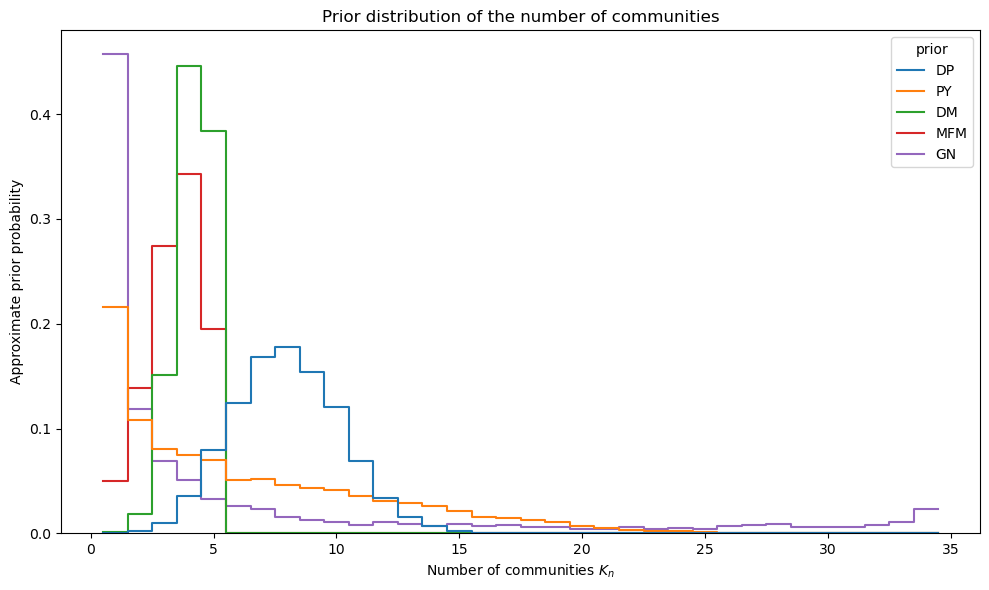

,prior,log_prior_true,K_true,sizes_true
0,DP,-31.485603,2,"[17, 17]"
1,PY,-28.537216,2,"[17, 17]"
2,DM,-28.548888,2,"[17, 17]"
3,MFM,-26.377086,2,"[17, 17]"
4,GN,-26.430417,2,"[17, 17]"


In [20]:
def simulate_partition(prior, n, rng):
    z = [0]
    sizes = [1]
    for i in range(1, n):
        probs = np.asarray(prior.predictive_probabilities(sizes),dtype=float)
        probs = probs / probs.sum()
        choice = rng.choice(len(probs), p=probs)
        if choice == len(sizes):
            sizes.append(1)
            z.append(len(sizes) - 1)
        else:
            sizes[choice] += 1
            z.append(choice)
    return np.asarray(z, dtype=int)

def simulate_prior_study(priors, n, n_sim=5000, seed=123):
    rng = np.random.default_rng(seed)
    records = []
    partitions = {}
    for name, prior in priors.items():
        samples = []
        for _ in range(n_sim):
            z = simulate_partition(prior, n, rng)
            samples.append(z)
            sizes = np.unique(z, return_counts=True)[1]
            records.append({
                "prior": name,
                "K": len(sizes),
                "largest_group": sizes.max(),
                "smallest_group": sizes.min(),
                "singleton_groups": np.sum(sizes == 1)})
        partitions[name] = samples
    return pd.DataFrame(records), partitions


prior_df, prior_samples = simulate_prior_study(priors, n=n, n_sim=5000, seed=123)
summary_prior = (prior_df.groupby("prior").agg(
        E_K=("K", "mean"),
        SD_K=("K", "std"),
        Median_K=("K", "median"),
        Q05=("K", lambda x: x.quantile(0.05)),
        Q95=("K", lambda x: x.quantile(0.95)),
        E_singletons=("singleton_groups", "mean"),
        E_largest_group=("largest_group", "mean")).round(3))
summary_prior

plt.figure(figsize=(10, 6))
sns.histplot(data=prior_df, x="K", hue="prior", stat="probability", common_norm=False, discrete=True, element="step", fill=False)
plt.xlabel(r"Number of communities $K_n$")
plt.ylabel("Approximate prior probability")
plt.title("Prior distribution of the number of communities")
plt.tight_layout()
plt.show()

comparison = pd.DataFrame([{
        "prior": name, "log_prior_true": prior.log_probability(z_true),
        "K_true": len(np.unique(z_true)), "sizes_true": str(np.unique(z_true, return_counts=True)[1].tolist())}
    for name, prior in priors.items()])
comparison

In [21]:
model = SBMModel(adjacency=Y, a=a, b=b)
config = SamplerConfig(n_iterations=15_000, burn_in=5_000,thin=5)
initial_partition = np.zeros(n, dtype=int)
def canonical_partition(z):
    mapping = {}
    result = []
    for label in np.asarray(z):
        if label not in mapping:
            mapping[label] = len(mapping)
        result.append(mapping[label])
    return np.asarray(result, dtype=int)
def extract_samples(result):
    samples = result["samples"]
    return [canonical_partition(z) for z in samples]

sampler_classes = {"Gibbs": GibbsSampler, "SplitMerge": SplitMergeSampler, "Chaperones": ChaperonesSampler}
inference_results = {}
for prior_name, prior in priors.items():
    for sampler_name, SamplerClass in sampler_classes.items():
        sampler = SamplerClass(model=model, prior=prior, config=config)
        result = sampler.fit(initial_partition=initial_partition.copy(), seed=123)
        samples = result["samples"]
        inference_results[(prior_name, sampler_name)] = {"result": result, "samples": samples}
        print(f"{prior_name:8s} | {sampler_name:12s} | "
            f"{len(samples)} samples")

DP       | Gibbs        | 2000 samples
DP       | SplitMerge   | 2000 samples
DP       | Chaperones   | 2000 samples
PY       | Gibbs        | 2000 samples
PY       | SplitMerge   | 2000 samples
PY       | Chaperones   | 2000 samples
DM       | Gibbs        | 2000 samples
DM       | SplitMerge   | 2000 samples
DM       | Chaperones   | 2000 samples
MFM      | Gibbs        | 2000 samples
MFM      | SplitMerge   | 2000 samples
MFM      | Chaperones   | 2000 samples
GN       | Gibbs        | 2000 samples
GN       | SplitMerge   | 2000 samples
GN       | Chaperones   | 2000 samples


In [22]:
posterior_records = []
for (prior_name, sampler_name), info in inference_results.items():
    for z in info["samples"]:
        posterior_records.append({"prior": prior_name, "algorithm": sampler_name, "K": len(np.unique(z))})
posterior_df = pd.DataFrame(posterior_records)
posterior_summary = (posterior_df.groupby(["prior", "algorithm"]).agg(E_K=("K", "mean"), SD_K=("K", "std"), Median_K=("K", "median"), 
         Q05=("K", lambda x: x.quantile(0.05)), Q95=("K", lambda x: x.quantile(0.95))).round(3))
posterior_summary

E_K   SD_K  Median_K  Q05  Q95
prior algorithm                                   
DM    Chaperones  5.000  0.000       5.0  5.0  5.0
      Gibbs       4.948  0.228       5.0  4.0  5.0
      SplitMerge  4.222  0.713       4.0  3.0  5.0
DP    Chaperones  5.480  0.638       5.0  5.0  7.0
      Gibbs       5.645  0.750       6.0  5.0  7.0
      SplitMerge  5.584  0.852       5.0  5.0  7.0
GN    Chaperones  5.167  0.404       5.0  5.0  6.0
      Gibbs       5.100  0.508       5.0  5.0  6.0
      SplitMerge  2.425  0.668       2.0  2.0  4.0
MFM   Chaperones  4.986  0.120       5.0  5.0  5.0
      Gibbs       4.938  0.240       5.0  4.0  5.0
      SplitMerge  4.698  0.586       5.0  3.0  5.0
PY    Chaperones  5.822  0.856       6.0  5.0  7.0
      Gibbs       5.870  0.840       6.0  5.0  7.0
      SplitMerge  5.993  1.034       6.0  5.0  8.0

In [23]:
recovery_records = []
for (prior_name, sampler_name), info in inference_results.items():
    ari_values = []
    nmi_values = []
    for z in info["samples"]:
        ari_values.append(adjusted_rand_score(z_true, z))
        nmi_values.append(normalized_mutual_info_score(z_true, z))
    recovery_records.append({
        "prior": prior_name,
        "algorithm": sampler_name,
        "ARI_mean": np.mean(ari_values),
        "ARI_sd": np.std(ari_values),
        "NMI_mean": np.mean(nmi_values),
        "NMI_sd": np.std(nmi_values)})
recovery_df = pd.DataFrame(recovery_records).round(4)
recovery_df.sort_values("ARI_mean", ascending=False)

,prior,algorithm,ARI_mean,ARI_sd,NMI_mean,NMI_sd
3,PY,Gibbs,0.4515,0.1547,0.5002,0.1040
5,PY,Chaperones,0.4312,0.1754,0.4871,0.1167
9,MFM,Gibbs,0.4274,0.1197,0.4983,0.0871
11,MFM,Chaperones,0.4234,0.1117,0.4969,0.0821
1,DP,SplitMerge,0.4227,0.0453,0.4536,0.0198
8,DM,Chaperones,0.4203,0.1122,0.4931,0.0832
14,GN,Chaperones,0.4200,0.1090,0.4941,0.0803
2,DP,Chaperones,0.4162,0.1295,0.4859,0.0892
12,GN,Gibbs,0.4141,0.1276,0.4876,0.0960
6,DM,Gibbs,0.4135,0.1320,0.4882,0.0954


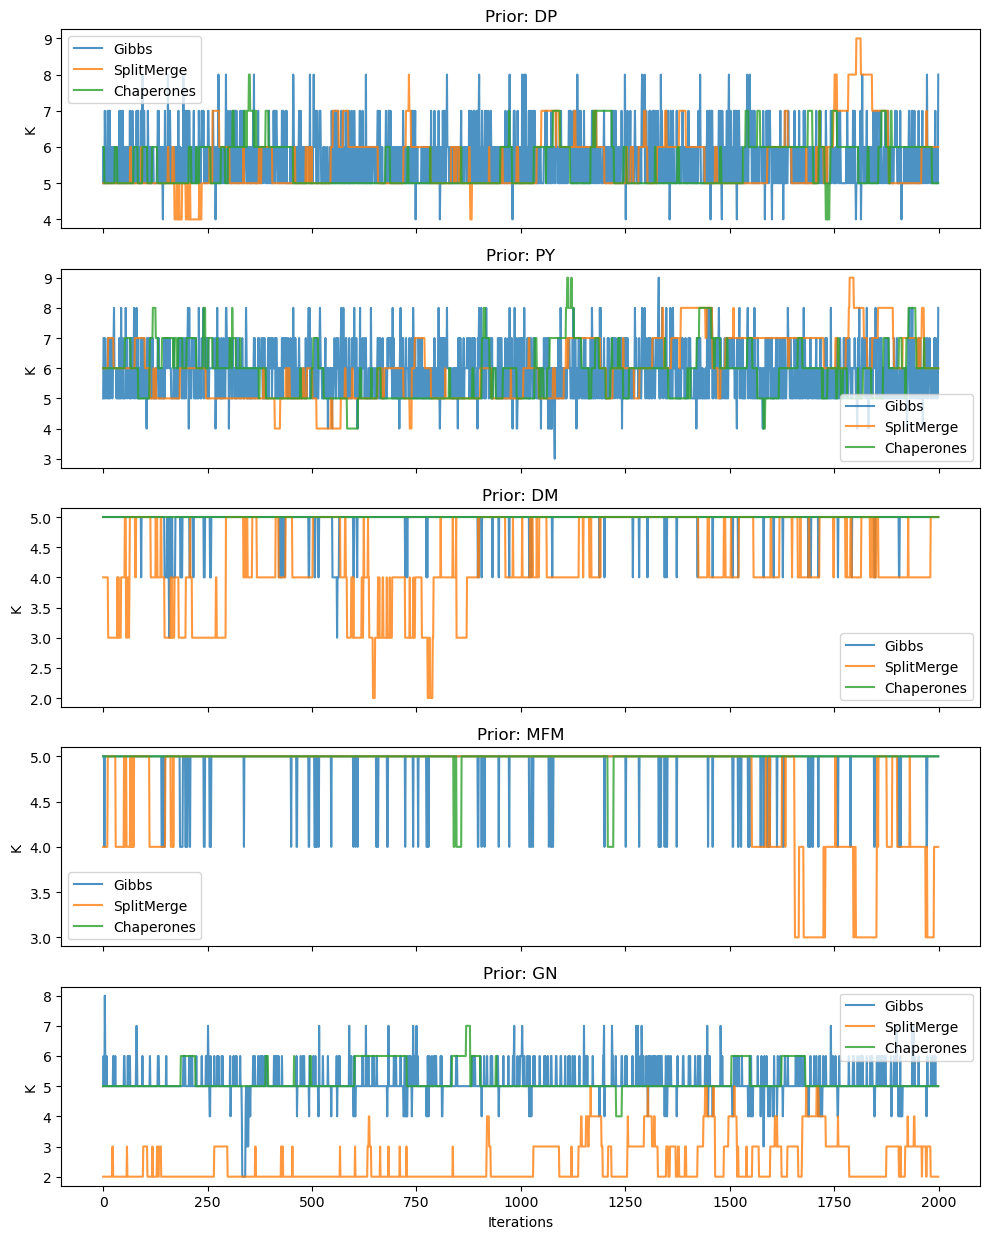

In [24]:
fig, axes = plt.subplots(len(priors), 1, figsize=(10, 2.5 * len(priors)), sharex=True)
for ax, prior_name in zip(axes, priors):
    for sampler_name in sampler_classes:
        samples = inference_results[(prior_name, sampler_name)]["samples"]
        K_trace = [len(np.unique(z)) for z in samples]
        ax.plot(K_trace, label=sampler_name, alpha=0.8)
    ax.set_title(f"Prior: {prior_name}")
    ax.set_ylabel("K")
    ax.legend()
axes[-1].set_xlabel("Iterations")
plt.tight_layout()
plt.show()

### Colombian politics